In [8]:
import pandas as pd
import numpy as np

# 1. Indian E-Commerce dataset load karein
df = pd.read_csv("data/raw/indian_ecommerce_100k.csv")

# 2. Total orders aur GMV (Gross Revenue) check karein
total_gmv_cr = df['order_value_inr'].sum() / 10000000
print(f"Total Transactions: {df.shape[0]:,} Rows | {df.shape[1]} Columns")
print(f"Total Marketplace GMV: ₹{total_gmv_cr:.2f} Crores\n")

# 3. Pehle 3 orders ki key details dekhein
df[['order_id', 'state', 'city', 'category', 'price_inr', 'payment_method', 'courier_partner']].head(3)


Total Transactions: 100,000 Rows | 21 Columns
Total Marketplace GMV: ₹61.96 Crores



,order_id,state,city,category,price_inr,payment_method,courier_partner
0,OD84437458,Telangana,Hyderabad,Beauty & Personal Care,383.80,UPI (PhonePe / GPay / Paytm),Delhivery
1,OD43704923,Gujarat,Rajkot,Mobiles & Accessories,896.44,Cash on Delivery (COD),Delhivery
2,OD30005727,Gujarat,Vadodara,Books & Stationery,283.82,Debit Card / Net Banking,Shadowfax


In [9]:
# 1. Check karein koi missing value toh nahi hai
missing = df.isnull().sum()
print("🔍 Missing Values Check:", missing[missing > 0].to_dict() if missing.sum() > 0 else "Zero Nulls (100% Complete Data!)")

# 2. Order Status Breakdown (Delivered vs RTO/Returned)
print("\n📦 Order Status Distribution (%):")
print(df['order_status'].value_counts(normalize=True).round(4) * 100)

# 3. Payment Methods Share (UPI vs COD vs Cards)
print("\n💳 Payment Methods Share (%):")
print(df['payment_method'].value_counts(normalize=True).round(4) * 100)


🔍 Missing Values Check: Zero Nulls (100% Complete Data!)

📦 Order Status Distribution (%):
order_status
Delivered         87.28
RTO / Returned    12.72
Name: proportion, dtype: float64

💳 Payment Methods Share (%):
payment_method
UPI (PhonePe / GPay / Paytm)    48.27
Cash on Delivery (COD)          27.79
Credit Card No-Cost EMI         14.03
Debit Card / Net Banking         9.91
Name: proportion, dtype: float64


In [10]:
# Audit dataset for missing records and data completeness
missing_counts = df.isnull().sum()
if missing_counts.sum() == 0:
    print("Data Integrity: No missing values detected across all columns.")
else:
    print("Columns with missing values:", missing_counts[missing_counts > 0].to_dict())

# Analyze fulfillment and return distribution
print("\nOrder Fulfillment Breakdown (%):")
print((df['order_status'].value_counts(normalize=True) * 100).round(2))

# Evaluate customer checkout payment preferences
print("\nPayment Method Distribution (%):")
print((df['payment_method'].value_counts(normalize=True) * 100).round(2))


Data Integrity: No missing values detected across all columns.

Order Fulfillment Breakdown (%):
order_status
Delivered         87.28
RTO / Returned    12.72
Name: proportion, dtype: float64

Payment Method Distribution (%):
payment_method
UPI (PhonePe / GPay / Paytm)    48.27
Cash on Delivery (COD)          27.79
Credit Card No-Cost EMI         14.03
Debit Card / Net Banking         9.91
Name: proportion, dtype: float64


In [11]:
# Feature Engineering: Compute order-level profit margin and loss flags
df['profit_margin_pct'] = np.where(df['order_value_inr'] > 0, (df['net_profit_inr'] / df['order_value_inr']) * 100, 0).round(2)
df['is_loss_making'] = df['net_profit_inr'] < 0

# Aggregate total corporate financial performance
total_profit_cr = df['net_profit_inr'].sum() / 10000000
overall_margin_pct = (df['net_profit_inr'].sum() / df['order_value_inr'].sum()) * 100
total_losses_cr = abs(df.loc[df['is_loss_making'], 'net_profit_inr'].sum()) / 10000000

print(f"Total Operating Profit: ₹{total_profit_cr:.2f} Crores")
print(f"Overall Net Profit Margin: {overall_margin_pct:.2f}%")
print(f"Cumulative Leaked Loss: ₹{total_losses_cr:.2f} Crores across {df['is_loss_making'].sum():,} loss-making orders")


Total Operating Profit: ₹11.85 Crores
Overall Net Profit Margin: 19.12%
Cumulative Leaked Loss: ₹0.13 Crores across 12,720 loss-making orders


Payment Mode Risk & Profitability Breakdown:
              payment_method  total_orders  rto_rate_pct  avg_net_profit  total_profit_lakhs
      Cash on Delivery (COD)         27794         25.02     1026.543871              285.32
     Credit Card No-Cost EMI         14029          8.14     1249.610352              175.31
UPI (PhonePe / GPay / Paytm)         48266          8.03     1237.247103              597.17
    Debit Card / Net Banking          9911          7.54     1281.546394              127.01


C:\Users\Pratham\AppData\Local\Temp\ipykernel_1008\3523397074.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=payment_diag, x='rto_rate_pct', y='payment_method', palette=bar_colors)


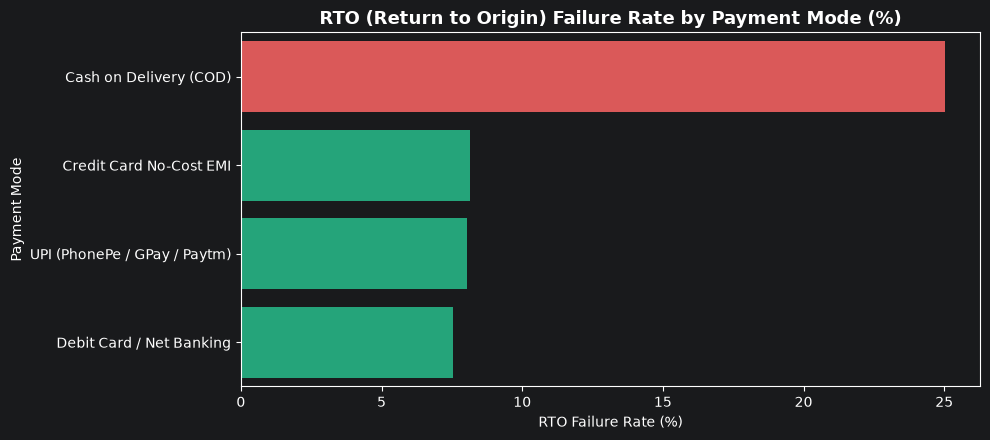

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group performance by payment method to diagnose RTO risk
payment_diag = df.groupby('payment_method').agg(
    total_orders=('order_id', 'count'),
    rto_rate_pct=('is_loss_making', lambda x: (x.mean() * 100).round(2)),
    avg_net_profit=('net_profit_inr', 'mean'),
    total_profit_lakhs=('net_profit_inr', lambda x: (x.sum() / 100000).round(2))
).reset_index().sort_values(by='rto_rate_pct', ascending=False)

print("Payment Mode Risk & Profitability Breakdown:")
print(payment_diag.to_string(index=False))

# Visualize RTO return rate across payment types
plt.figure(figsize=(10, 4.5))
bar_colors = ['#EF4444' if 'COD' in p else '#10B981' for p in payment_diag['payment_method']]
sns.barplot(data=payment_diag, x='rto_rate_pct', y='payment_method', palette=bar_colors)
plt.title("RTO (Return to Origin) Failure Rate by Payment Mode (%)", fontsize=13, fontweight='bold')
plt.xlabel("RTO Failure Rate (%)")
plt.ylabel("Payment Mode")
plt.tight_layout()
plt.show()


Courier Partner Reliability Ranking:
courier_partner  shipment_volume  delay_rate_pct  avg_review_score
   Ecom Express            20055            8.26          3.809873
      Delhivery            44833            8.33          3.793255
       BlueDart            25036            8.39          3.807996
      Shadowfax            10076            8.64          3.807463


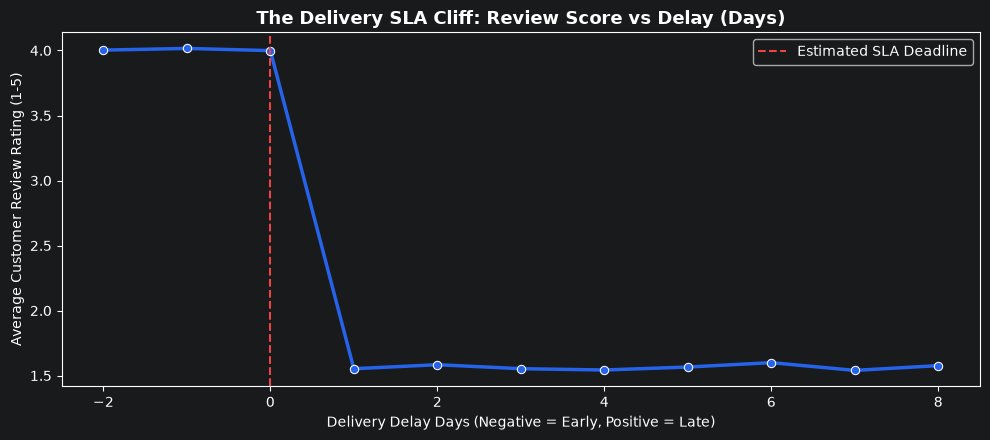

In [13]:
# Analyze courier partner operational reliability and SLA adherence
courier_perf = df.groupby('courier_partner').agg(
    shipment_volume=('order_id', 'count'),
    delay_rate_pct=('is_delayed', lambda x: (x.mean() * 100).round(2)),
    avg_review_score=('review_score', 'mean')
).reset_index().sort_values(by='delay_rate_pct', ascending=True)

print("Courier Partner Reliability Ranking:")
print(courier_perf.to_string(index=False))

# Plot delivery latency vs customer review score impact
plt.figure(figsize=(10, 4.5))
delay_rating_trend = df.groupby('delivery_delay_days')['review_score'].mean().reset_index()
sns.lineplot(data=delay_rating_trend, x='delivery_delay_days', y='review_score', marker='o', color='#2563EB', linewidth=2.5)
plt.axvline(0, color='#EF4444', linestyle='--', linewidth=1.5, label='Estimated SLA Deadline')
plt.title("The Delivery SLA Cliff: Review Score vs Delay (Days)", fontsize=13, fontweight='bold')
plt.xlabel("Delivery Delay Days (Negative = Early, Positive = Late)")
plt.ylabel("Average Customer Review Rating (1-5)")
plt.legend()
plt.tight_layout()
plt.show()
